In [ ]:
import numpy as np
import pandas as pd
import tifffile as tiff
import sys
import plotly.graph_objects as go
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost
import xarray as xr

# stolen from phasor.py
from phasorpy.plot import PhasorPlot  
from phasorpy.datasets import fetch


# personal stufF
import lib.randgen
import lib.my_stats

# program specific
import lib.phasorpyplot as phplt

# 1. Exponential data generation

In [2]:
τ_true = 4 # ns
N_evt = 10000
T_laser = 12.5  #ns

exp1data = np.random.exponential(scale = τ_true, size = N_evt) % T_laser   # exp1data = SINGLE exponential data
time_bins = np.linspace(0, T_laser, 256)
n, _ = np.histogram(exp1data, bins = time_bins)
    # xe = bin edges, n = bin heights
    # Removed xe bc I'm using time_bins to calculate bins

# Annotation: in line 5, / T_laser is used


<h3> Binned NNL fit (only made for comparison purposes)

In [3]:
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 

#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(exp1data)

c_binned = cost.ExtendedBinnedNLL(n, time_bins, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("Params")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\nStats")
lib.my_stats.minuit_stats(m)

# NB: using 256 bins as most data I found is resampled from 4096 to 256

Params


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,2.62e3,0.04e3,,,0.001,,
1,τ,3.99,0.05,,,0.001,,



Stats
chi-squared: 263.95
reduced chi-squared: 1.04
dof: 253.00
p-value: 0.31


# 2. Phasor plot and noise addition

Functions for calculating and plotting phasors (given a histogram)

In [4]:
def phasor_calc (n, harm_n = 1):   # given a histogram n (xe), calculates the phasor coordinates G and S

    fft_vals = np.fft.rfft(n)
    fft_norm = fft_vals / fft_vals[0]
    
    G, S = np.real(fft_norm[harm_n]), -np.imag(fft_norm[harm_n])

    return G, S




###################################################################################################



def add_noise(counts, snr_db):  # Adds GAUSSIAN NOISE (why not Poisson? Need to check)

    rng = np.random.default_rng()   
    snr_linear = 10 ** (snr_db / 10)  # convert SNR from dB to linear scale 

    sig_power = np.mean(counts ** 2, axis = 0) 
    noise_std = np.sqrt(sig_power / snr_linear)
    noise = rng.standard_normal(counts.shape) * noise_std
    
    return np.clip(counts + noise, 0, None)




###################################################################################################


def phasor_calc_mix(G_array, S_array, fractions):

    G_array = np.asarray(G_array)
    S_array = np.asarray(S_array)
    fractions = np.asarray(fractions, dtype=float)

    fractions /= np.sum(fractions)  # safety feature
    G_mix, S_mix = np.sum(fractions * G_array), np.sum(fractions * S_array)

    return G_mix, S_mix



###################################################################################################




def projection_length(point, A, B):   # asarray converts points/lines (Pandas dataframes) to a numpy array
    
    """
    Projects a point onto a line segment and returns the segment lengths.
    """

    P = np.asarray(point, dtype = float)      # points that is to be projected  
    A, B = np.asarray(line_start, dtype = float), np.asarray(line_end, dtype = float)   # extremes of the full segment (formed by tau of the 2 exponential decays)

    line_vector = B - A
    H_factor = np.dot(P - A, line_vector) / np.dot(line_vector, line_vector)  # valued 0 to 1 (how far from A on the segment H is), H is projected point
    H = A + H_factor * line_vector

    segmA, segmB = np.linalg.norm(H - A), np.linalg.norm(B - H)       # segments lengths

    return segmA, segmB



###################################################################################################



def projection_area(point, A, B, C):   # asarray converts points/lines (Pandas dataframes) to a numpy array

    """
    Works the same as the previous function but for 3 exponential decays. Calculates areas on the phasor plane corresponding to each fluorophor
    """

    point, A, B, C = map(np.asarray, (point, A, B, C))
    big_triangle = triangle_area(A, B, C)

    return (
        triangle_area(point, B, C) / big_triangle,
        triangle_area(point, C, A) / big_triangle,
        triangle_area(point, A, B) / big_triangle,
    )


###################################################################################################



def triangle_area(p1, p2, p3):              # self explainatory

    p1, p2, p3 = map(np.asarray, (p1, p2, p3))

    return 0.5 * abs(p1[0] * (p2[1] - p3[1]) + p2[0] * (p3[1] - p1[1]) + p3[0] * (p1[1] - p2[1]))


<h3> Single exponential

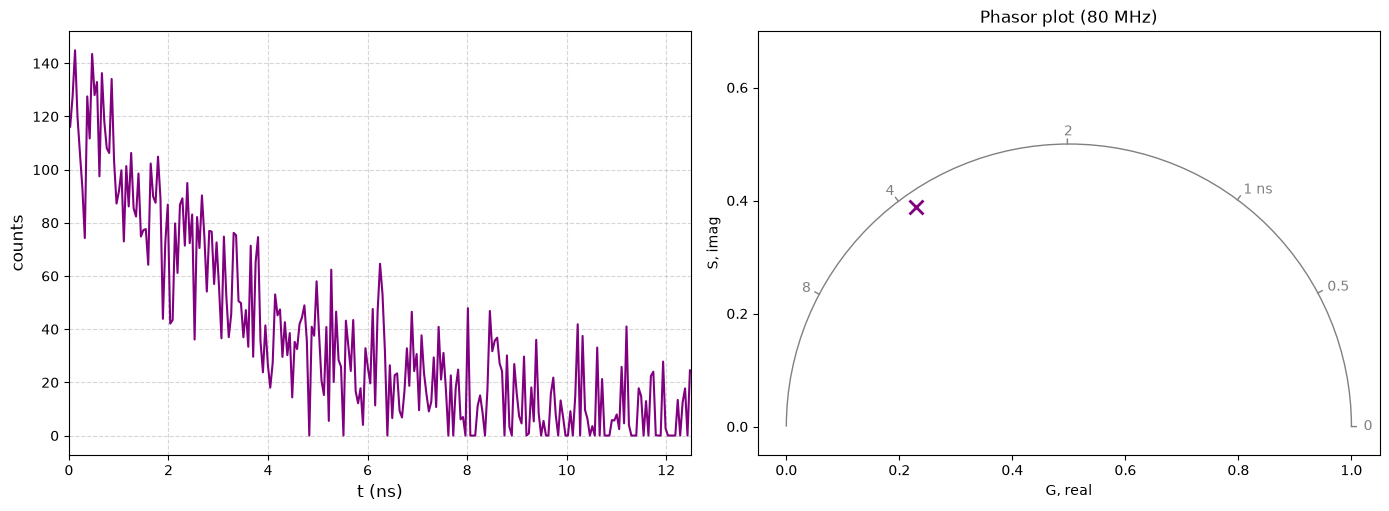

In [5]:
noise_flag = True     # toggle to add noise, higher snr = less noise
snr_db = 10

if noise_flag:
    n_noisy = add_noise(n, snr_db=snr_db)
else:
    n_noisy = n


#phasors = [phasor_calc(n, harm_n) for harm_n in range(1, 4)]  # calculate phasors for the first three harmonics
#data_and_phasor_plot(xe, n, phasors[0][0], phasors[0][1], T_laser=12.5)  # [0][1] = first harmonic, S

phasors = phasor_calc(n_noisy)  # commented the version that displays multiple harmonics

phplt.data_and_phasor_plot(time_bins, n_noisy, phasors[0], phasors[1], T_laser, exp1data)


<h3> Double exponential

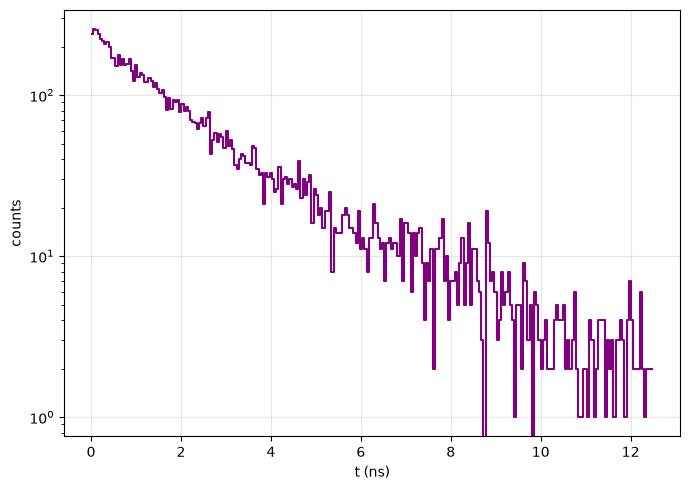

In [6]:
# Usual stuff, now for 2 curves

τ_true1, τ_true2 = 1.5, 4.0
f1 = 0.6    # ratio of intensity for the 2 curves

N_evt1 = int(N_evt * f1)   # ratio of events for the 2 curves 
N_evt2 = N_evt - N_evt1

exp2data1 = np.random.exponential(scale = τ_true1, size = N_evt1)
exp2data2 = np.random.exponential(scale = τ_true2, size = N_evt2)

time_bins = np.linspace(0, T_laser, 256)
t = 0.5 * (time_bins[:-1] + time_bins[1:])

n1, _ = np.histogram(exp2data1 % T_laser, bins = time_bins)
n2, _ = np.histogram(exp2data2 % T_laser, bins = time_bins)
n_mix = n1 + n2  


phplt.plot_decay(time_bins, n_mix)

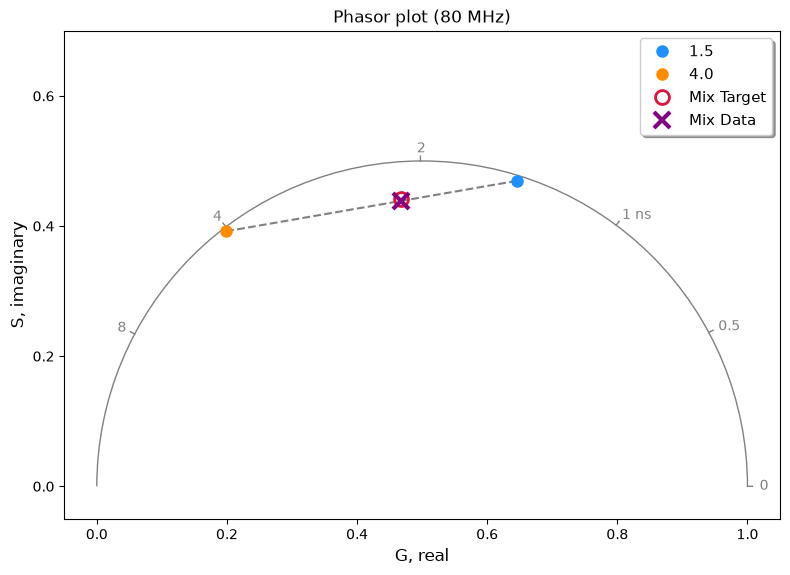

In [7]:
(G1, S1), (G2, S2), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n_mix))              # G1, G2 = phasor_calc(n1), etc
(G1_true, S1_true), (G2_true, S2_true) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))    # Here n values are taken from pure exponential in t

G_true, S_true = phasor_calc_mix([G1_true, G2_true], [S1_true, S2_true], [f1, 1 - f1])

points_mix = [
    {'G': G1, 'S': S1, 'label': f'{τ_true1}', 'color': 'dodgerblue'},
    {'G': G2, 'S': S2, 'label': f'{τ_true2}', 'color': 'darkorange'},
    {'G': G_true, 'S': S_true, 'label': 'Mix Target', 'marker': 'o', 'markerfacecolor': 'none', 'markeredgecolor': 'crimson', 'markeredgewidth': 2, 'markersize': 10, 'zorder': 2},
    {'G': G_mix, 'S': S_mix, 'label': 'Mix Data', 'color': 'purple', 'marker': 'x', 'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
]
lines_mix = [
    {'G': [G1, G2], 'S': [S1, S2], 'color': 'gray', 'ls': '--', 'lw': 1.5}
]

phplt.universal_phasor_plot(T_laser, points = points_mix, lines = lines_mix)


<h3> double exponential - segments length ratio

In [8]:
line_start = (G1, S1)   # first phasor
line_end = (G2, S2)     # second phasor

target_seg1, target_seg2 = projection_length(
    point = (G_true, S_true),
    A = line_start,
    B = line_end
)

data_seg1, data_seg2 = projection_length(
    point = (G_mix, S_mix),
    A = line_start,
    B = line_end
)

print("Mix Target:")
print(f"  f1: {target_seg1:.6f}")
print(f"  f2: {target_seg2:.6f}")

print("\nMix Data:")
print(f"  f1: {data_seg1:.6f}")
print(f"  f2: {data_seg2:.6f}")

Mix Target:
  f1: 0.180133
  f2: 0.273026

Mix Data:
  f1: 0.181263
  f2: 0.271895


<h3> double/triple exponential

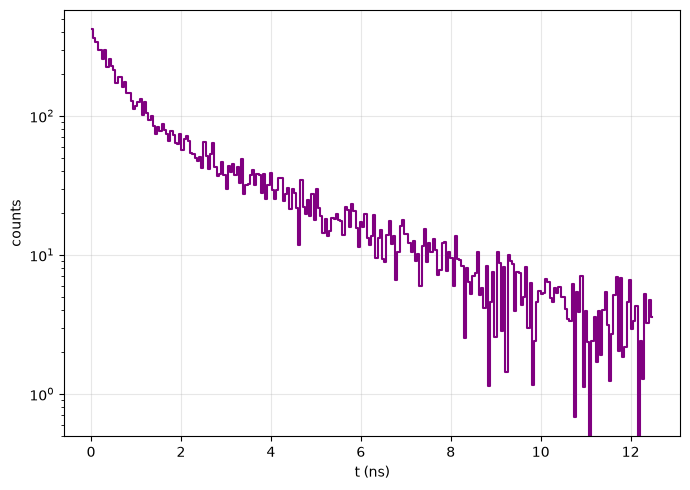

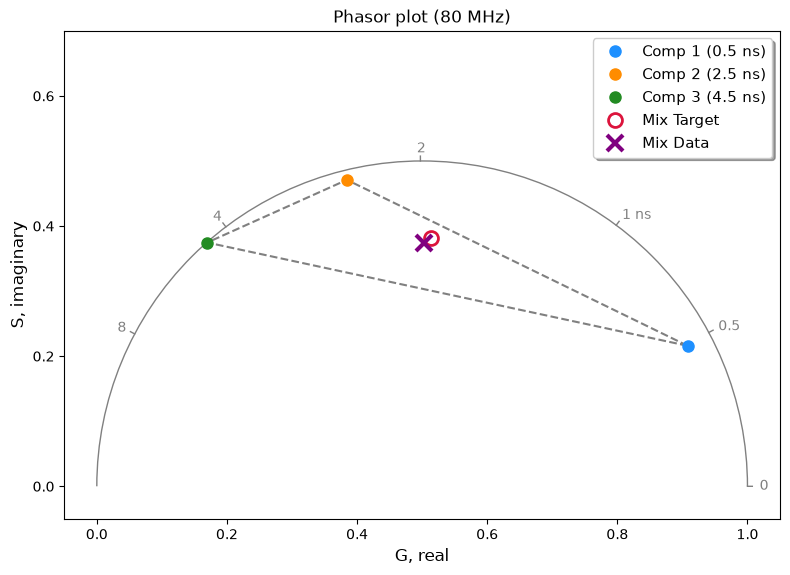

In [9]:
n_comp = 3         # SWITCH BETWEEN 2 AND 3 COMPONENTS (3 suggested for testing)
noise_flag = True
snr_db = 30

if n_comp == 2:

    τ_true1, τ_true2 = 1.5, 4.0
    f1 = 0.6
    f2 = 1.0 - f1

    N_evt1 = int(N_evt * f1)
    N_evt2 = N_evt - N_evt1

    expdata1 = np.random.exponential(scale = τ_true1, size = N_evt1)
    expdata2 = np.random.exponential(scale = τ_true2, size = N_evt2)

    n1_clean, _ = np.histogram(expdata1 % T_laser, bins = time_bins)
    n2_clean, _ = np.histogram(expdata2 % T_laser, bins = time_bins)

    if noise_flag:
        n1 = add_noise(n1_clean, snr_db = snr_db)
        n2 = add_noise(n2_clean, snr_db = snr_db)
    else:
        n1 = n1_clean.copy()
        n2 = n2_clean.copy()

    n_mix = n1 + n2

    t = 0.5 * (time_bins[:-1] + time_bins[1:])

    (G1, S1), (G2, S2), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n_mix))      # phasors of data values

    (G1_true, S1_true), (G2_true, S2_true) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))     # phasors of theoric values

    G_true, S_true = phasor_calc_mix([G1_true, G2_true], [S1_true, S2_true], [f1, f2])      # final phasor of theoric value


    # DATAFRAME CREATION

    points_mix = [
        {'G': G1, 'S': S1, 'label': f'Comp 1 ({τ_true1} ns)', 'color': 'dodgerblue'},
        {'G': G2, 'S': S2, 'label': f'Comp 2 ({τ_true2} ns)', 'color': 'darkorange'},
        {'G': G_true, 'S': S_true, 'label': 'Mix Target',
         'marker': 'o', 'markerfacecolor': 'none',
         'markeredgecolor': 'crimson', 'markeredgewidth': 2,
         'markersize': 10, 'zorder': 2},
        {'G': G_mix, 'S': S_mix, 'label': 'Mix Data',
         'color': 'purple', 'marker': 'x',
         'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
    ]

    lines_mix = [
        {'G': [G1, G2], 'S': [S1, S2],
         'color': 'gray', 'ls': '--', 'lw': 1.5}
    ]

elif n_comp == 3:

    τ_true1, τ_true2, τ_true3 = 0.5, 2.5, 4.5
    f1, f2 = 0.3, 0.5
    f3 = 1.0 - f1 - f2

    N_evt1 = int(N_evt * f1)
    N_evt2 = int(N_evt * f2)
    N_evt3 = N_evt - N_evt1 - N_evt2

    expdata1 = np.random.exponential(scale = τ_true1, size = N_evt1)
    expdata2 = np.random.exponential(scale = τ_true2, size = N_evt2)
    expdata3 = np.random.exponential(scale = τ_true3, size = N_evt3)

    n1_clean, _ = np.histogram(expdata1 % T_laser, bins = time_bins)
    n2_clean, _ = np.histogram(expdata2 % T_laser, bins = time_bins)
    n3_clean, _ = np.histogram(expdata3 % T_laser, bins = time_bins)


    # ADDING NOISE

    if noise_flag:              
        n1 = add_noise(n1_clean, snr_db = snr_db)
        n2 = add_noise(n2_clean, snr_db = snr_db)
        n3 = add_noise(n3_clean, snr_db = snr_db)
    else:
        n1 = n1_clean.copy()
        n2 = n2_clean.copy()
        n3 = n3_clean.copy()

    n_mix = n1 + n2 + n3

    t = 0.5 * (time_bins[:-1] + time_bins[1:])

    (G1, S1), (G2, S2), (G3, S3), (G_mix, S_mix) = map(
        phasor_calc,
        (n1, n2, n3, n_mix)
    )

    (G1_true, S1_true), (G2_true, S2_true), (G3_true, S3_true) = map(
        phasor_calc,
        (
            np.exp(-t / τ_true1),
            np.exp(-t / τ_true2),
            np.exp(-t / τ_true3)
        )
    )

    G_true, S_true = phasor_calc_mix(
        [G1_true, G2_true, G3_true],
        [S1_true, S2_true, S3_true],
        [f1, f2, f3]
    )

    points_mix = [
        {'G': G1, 'S': S1, 'label': f'Comp 1 ({τ_true1} ns)', 'color': 'dodgerblue'},
        {'G': G2, 'S': S2, 'label': f'Comp 2 ({τ_true2} ns)', 'color': 'darkorange'},
        {'G': G3, 'S': S3, 'label': f'Comp 3 ({τ_true3} ns)', 'color': 'forestgreen'},
        {'G': G_true, 'S': S_true, 'label': 'Mix Target',
         'marker': 'o', 'markerfacecolor': 'none',
         'markeredgecolor': 'crimson', 'markeredgewidth': 2,
         'markersize': 10, 'zorder': 2},
        {'G': G_mix, 'S': S_mix, 'label': 'Mix Data',
         'color': 'purple', 'marker': 'x',
         'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
    ]

    lines_mix = [
        {'G': [G1, G2, G3, G1],
         'S': [S1, S2, S3, S1],
         'color': 'gray', 'ls': '--', 'lw': 1.5}
    ]

phplt.plot_decay(time_bins, n_mix)
phplt.universal_phasor_plot(T_laser, points=points_mix, lines=lines_mix)

Osservazione: intensità più piccola = errore più grande (ma va?), perché il rumore è generato sempre con la stessa ampiezza e quindi diventa più importante per dati "piccoli"


<h3> double/triple exponential - area ratios

In [10]:
# Only works for triple exponential!

target_areas = projection_area(
    point = (G_true, S_true),
    A = (G1_true, S1_true),
    B = (G2_true, S2_true),
    C = (G3_true, S3_true),
)

data_areas = projection_area(
    point = (G_mix, S_mix),
    A = (G1, S1),
    B = (G2, S2),
    C = (G3, S3),
)

# print(data_areas)
# print(target_areas)

print("Mix Target:")
for i, area in enumerate(target_areas, 1):
    print(f"  f{i}: {area}")

print("\nMix Data:")
for i, area in enumerate(data_areas, 1):
    print(f"  f{i}: {area}")

Mix Target:
  f1: 0.30000000000000004
  f2: 0.4999999999999998
  f3: 0.20000000000000034

Mix Data:
  f1: 0.30705754215567743
  f2: 0.4960128002558766
  f3: 0.1969296575884458


# 3. Simulation of data + IRF convolution

2 parole su cosa devo fare per vedere se ho capito. Spegazione presa dal file mmc5.pdf

IRF = Instrument Response Function, è la funzione di risposta al laser data dal rivelatore. È fondamentalmente il profilo temporale della risposta del sistema di rilevamento a un impulso laser brevissimo.

Il sistema di rilevamento infatti presenta sempre un errore nella risposta intrinseco dovuto a motivi fisici/elettronici (e quindi non riproducibile).
Studiare l'IRF permette di ottenere informazioni su questo errore e dunque correggere anche i dati raccolti.

Nel piano temporale: decadimento rilevato = convoluzione(decadimento reale, IRF)
Nel piano dei fasori: z_tot = z_exp * z_IRF




<h3> Functions for this section

In [11]:
def irf_generation(σ, μ, counts, T_laser, num_bins = 30):       # gaussian IRF

    time_bins = np.linspace(0, T_laser, num_bins)
    
    irf = np.exp(-((time_bins - μ)**2) / (2 * σ**2))
    
    irf /= np.sum(irf)
    irf *= counts
    
    return time_bins, irf



#############################################################################################################



def simulation_with_IRF(exp1data1, irf, counts, noise_flag, snr_db): 

    n_bins = len(irf)
    
    # Use a circular convolution so the signal stays consistent with the laser period.
    convol = np.fft.ifft(np.fft.fft(exp1data1) * np.fft.fft(irf)).real      # Here I'm using the phasor method instead of 
                                                                            # np.convolve (slow + doesn't handle periodicity)

    convol = np.clip(convol, 0, None)
    convol = (convol / np.sum(convol)) * counts  # Normalization
    
    #NOISEEEEE
    if noise_flag: noisy_signal = add_noise(convol, snr_db) 
    else: noisy_signal = convol
    
    return convol, noisy_signal




##############################################################################################################




def phasor_deconv(G_meas, S_meas, G_irf, S_irf): 
 
    z_meas = G_meas + 1j * S_meas       # imaginary unit i = 1j
    z_irf = G_irf + 1j * S_irf
    
    z_deconvol = z_meas / z_irf       # in phasor plane, convolution = moltiplication
    
    G_deconvol, S_deconvol = np.real(z_deconvol), np.imag(z_deconvol)
    
    return G_deconvol, S_deconvol


<h3> Simulation of binned data (single exponential) + gaussian IRF 

In [12]:
# Testing the functions

T_laser = 12.5
N_evt1 = 10000
τ_true1 = 4       

μ, σ = 0.3, 0.1

exp1data1 = np.random.exponential(scale = τ_true, size = N_evt) % T_laser
time_bins = np.linspace(0, T_laser, 4096)
n1, xe1= np.histogram(exp1data1, bins = time_bins)   

noise_bool1, snr_db1 = True, 20  

time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal, noisy_signal = simulation_with_IRF(n1, irf, N_evt1, noise_bool1, snr_db1)


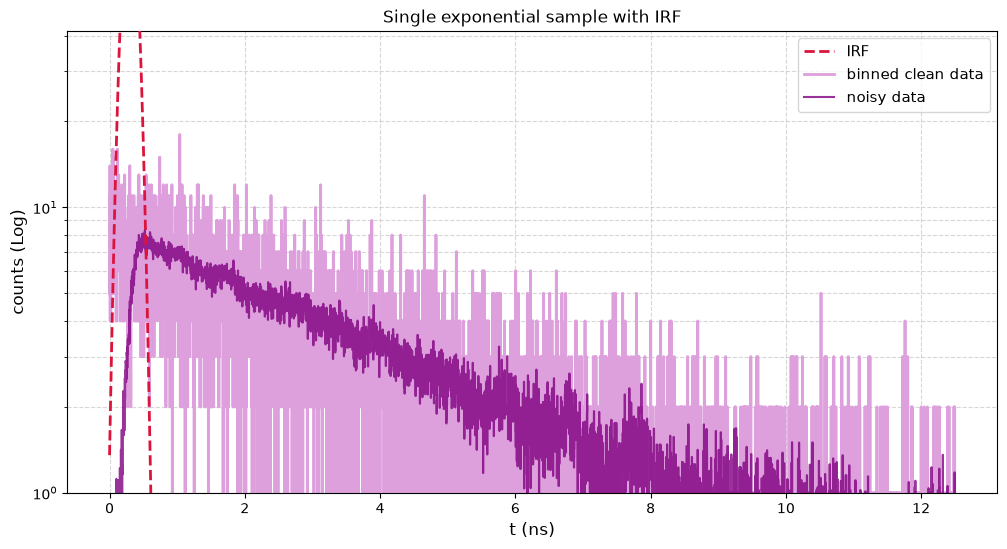

In [13]:
plt.figure(figsize = (12, 6))

signal_max = np.max(noisy_signal)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(xe1[:-1], n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal, where = 'mid', label = 'noisy data', color = 'purple', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)

plt.title('Single exponential sample with IRF')

plt.show()


# È normale che sia così wiggly??

<h3> Deconvolution of signal (single exponential)

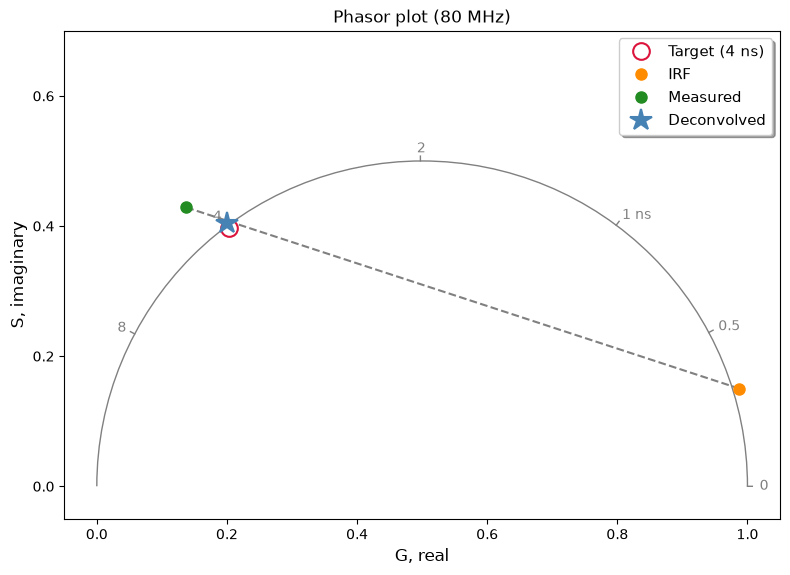

In [14]:
G_meas, S_meas = phasor_calc(noisy_signal, harm_n = 1)      # tot signal phasor
G_irf, S_irf = phasor_calc(irf, harm_n = 1)     # irf phasor

G_deconvol, S_deconvol = phasor_deconv(G_meas, S_meas, G_irf, S_irf)     # cleaned phasor (deconv of signal and irf)

n_true = np.exp(-t / τ_true)
G_true, S_true = phasor_calc(n_true)

points_mix1 = [
    {
        'G': G_true, 
        'S': S_true, 
        'label': f'Target ({τ_true} ns)', 
        'color': 'crimson', 
        'marker': 'o', 
        'markersize': 12, 
        'markeredgewidth': 1.5, 
        'markerfacecolor': 'white'
    },
    {
        'G': G_irf, 
        'S': S_irf, 
        'label': 'IRF', 
        'color': 'darkorange', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_meas, 
        'S': S_meas, 
        'label': 'Measured', 
        'color': 'forestgreen', 
        'marker': 'o', 
        'markersize': 8, 
    },
    {
        'G': G_deconvol, 
        'S': S_deconvol, 
        'label': 'Deconvolved', 
        'color': 'steelblue', 
        'marker': '*', 
        'markersize': 16, 
        'markeredgewidth': 1.5
    }
]

lines_mix1 = [
    {'G': [G_irf, G_meas], 'S': [S_irf, S_meas], 'color': 'gray', 'ls': '--', 'lw': 1.5}
]

phplt.universal_phasor_plot(T_laser, points = points_mix1, lines = lines_mix1)

<h3> Simulation of binned data (double exponential) + gaussian IRF 

Here I will be recycling some variables from previous cells. They are commented here so they can be re-defined if necessary

In [15]:
# --- FROM 2-EXP SIMULATION

τ_true1, τ_true2 = 4.0, 2

f1 = 0.7    # ratio of intensity for the 2 curves

N_evt1 = int(N_evt * f1)   # ratio of events for the 2 curves 
N_evt2 = N_evt - N_evt1

exp2data1 = np.random.exponential(scale = τ_true1, size = N_evt1)
exp2data2 = np.random.exponential(scale = τ_true2, size = N_evt2)

time_bins = np.linspace(0, T_laser, 4096)
t = 0.5 * (time_bins[:-1] + time_bins[1:])

n1, _ = np.histogram(exp2data1 % T_laser, bins = time_bins)
n2, _ = np.histogram(exp2data2 % T_laser, bins = time_bins)
n_mix = n1 + n2  


# --- FROM EXP + IRF CONVOLUTION

μ, σ = 0.25, 0.1
noise_bool1, snr_db1 = True, 20  
time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal1, noisy_signal1 = simulation_with_IRF(n_mix, irf, N_evt1, noise_bool1, snr_db1)

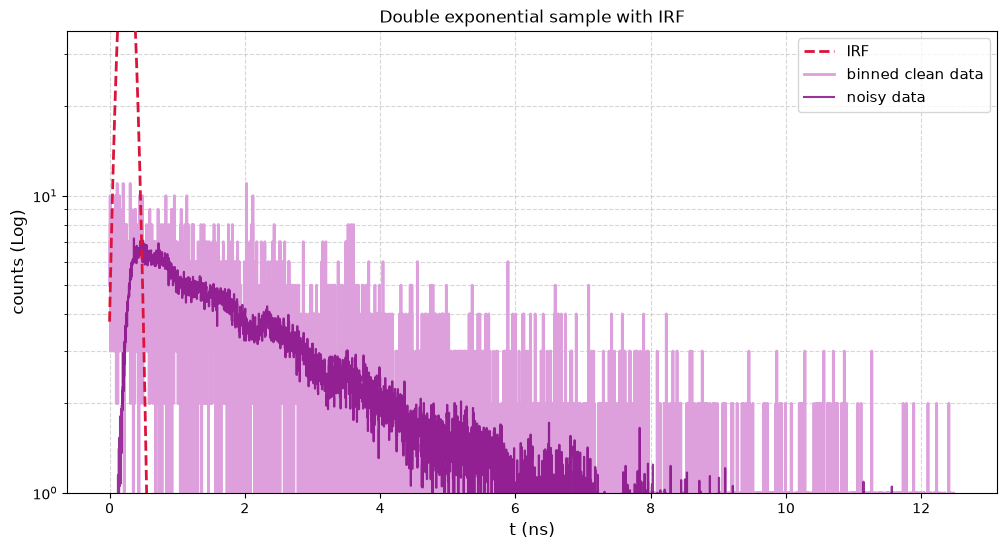

In [16]:
plt.figure(figsize = (12, 6))

signal_max = np.max(noisy_signal1)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(time_bins, n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal1, where = 'mid', label = 'noisy data', color = 'purple', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)
plt.title('Double exponential sample with IRF')

plt.show()

<h3> Deconvolution of signal (double exponential)


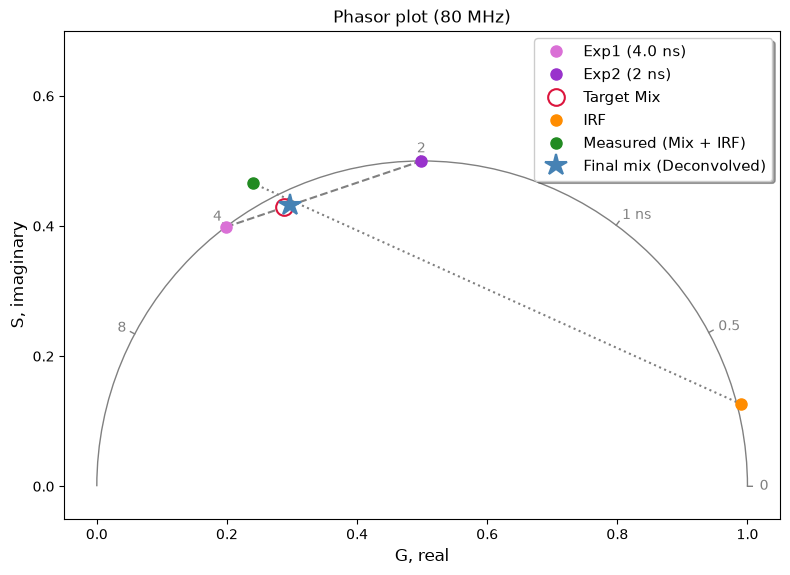

In [17]:
G_irf, S_irf = phasor_calc(irf)
G_meas, S_meas = phasor_calc(noisy_signal1)
G_deconvol, S_deconvol = phasor_deconv(G_meas, S_meas, G_irf, S_irf)

(G1t, S1t), (G2t, S2t) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))

G_target, S_target = phasor_calc_mix([G1t, G2t], [S1t, S2t], [f1, 1 - f1])

points_mix2 = [
    {
        'G': G1t, 
        'S': S1t, 
        'label': f'Exp1 ({τ_true1} ns)', 
        'color': 'orchid', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G2t, 
        'S': S2t, 
        'label': f'Exp2 ({τ_true2} ns)', 
        'color': 'darkorchid', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_target, 
        'S': S_target, 
        'label': 'Target Mix', 
        'color': 'crimson', 
        'marker': 'o', 
        'markersize': 12, 
        'markeredgewidth': 1.5, 
        'markerfacecolor': 'white'
    },
    {
        'G': G_irf, 
        'S': S_irf, 
        'label': 'IRF', 
        'color': 'darkorange', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_meas, 
        'S': S_meas, 
        'label': 'Measured (Mix + IRF)', 
        'color': 'forestgreen', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_deconvol, 
        'S': S_deconvol, 
        'label': 'Final mix (Deconvolved)', 
        'color': 'steelblue', 
        'marker': '*', 
        'markersize': 16, 
        'markeredgewidth': 1.5
    }
]

lines_mix2 = [
    {'G': [G1t, G2t], 'S': [S1t, S2t], 'color': 'gray', 'ls': '--', 'lw': 1.5},
    {'G': [G_irf, G_meas], 'S': [S_irf, S_meas], 'color': 'gray', 'ls': ':', 'lw': 1.5}
]

phplt.universal_phasor_plot(T_laser, points = points_mix2, lines = lines_mix2)

In [18]:
# Segmento teorico tra i due componenti
line_start = (G1t, S1t)
line_end = (G2t, S2t)

# Punto teorico e punto effettivo deconvoluto
target_segA, target_segB = projection_length(
    point=(G_target, S_target),
    A=line_start,
    B=line_end
)

effective_segA, effective_segB = projection_length(
    point=(G_deconvol, S_deconvol),
    A=line_start,
    B=line_end
)

# La frazione del componente 1 è la distanza dal punto al componente 2
f1_theory = target_segB / (target_segA + target_segB)
f2_theory = target_segA / (target_segA + target_segB)

f1_effective = effective_segB / (effective_segA + effective_segB)
f2_effective = effective_segA / (effective_segA + effective_segB)

print("Target ratios:")
print(f"  f1 = {f1_theory:.6f}")
print(f"  f2 = {f2_theory:.6f}")

print("\nMix ratios:")
print(f"  f1 = {f1_effective:.6f}")
print(f"  f2 = {f2_effective:.6f}")

Target ratios:
  f1 = 0.700000
  f2 = 0.300000

Mix ratios:
  f1 = 0.671502
  f2 = 0.328498


# 4. Working on an imported image - incomplete

<h3> Functions for this section

In [19]:
def extract_irf(calib_image, τ_fluor, T_laser): 

    ''' Given a calibration image with a known fluorescence lifetime, extracts the IRF phasor coordinates '''  

    tot_calib = calib_image.sum(dim = ("x", "y"))
    G_ref, S_ref = phasor_calc(tot_calib) 

    ω = 2 * np.pi / T_laser
    ωτ = ω * τ_fluor
    
    G_true = 1 / (1 + ωτ**2)
    S_true = ωτ / (1 + ωτ**2)
    G_irf, S_irf = phasor_deconv(G_ref, S_ref, G_true, S_true)
    
    return G_irf, S_irf



##############################################################################################################




def image_phasor_calc(image, harm = 1):

    '''Calculates the phasor coordinates for each pixel in a [t, x, y] image.'''

    fft_result = xr.DataArray(
        np.fft.rfft(image.values, axis=0),
        dims = ("frequency", "x", "y"),
        coords = {
            "x": image.coords["x"],
            "y": image.coords["y"],
        },
    )

    fft0 = fft_result.isel(frequency=0).real            # fft0 = DC = intensity = total photons per pixel
    fft0 = fft0.where(fft0 != 0, 1e-10)                 # crash fix - "fills" 0 values (empty bins) with very low count

    G_img = fft_result.isel(frequency=harm).real / fft0
    S_img = -fft_result.isel(frequency=harm).imag / fft0

    return G_img, S_img, fft0



##############################################################################################################




def filter_image_phasors(image, threshold_pct=0.05):

    ''' Mask for bg noise: higher_threshold = higher noise '''

    G_img, S_img, fft0 = image_phasor_calc(image)

    count_peak = fft0.max().item()
    threshold = count_peak * threshold_pct

    mask = fft0 > threshold
    
    print(f"Max count: {count_peak:.0f} γ. Threshold: {threshold:.0f} γ.")  
    print(f"Pixels over threshold: {int(mask.sum())}/{mask.size}")

    G_valid = G_img.where(mask).stack(pixel = ("x", "y")).dropna("pixel")     
    S_valid = S_img.where(mask).stack(pixel = ("x", "y")).dropna("pixel")

    return G_valid, S_valid



##############################################################################################################



def cloud_data(G_valid: xr.DataArray, S_valid: xr.DataArray):

    """
    Calculates average point and standard deviation of a cloud of data
    """

    ds = xr.Dataset({"G": G_valid, "S": S_valid})      # dataset of G and S combined
    
    return ds.mean(), ds.std()

<h3> Incomplete test on image 1

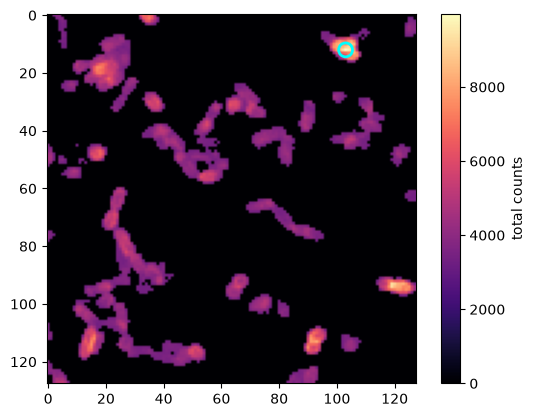

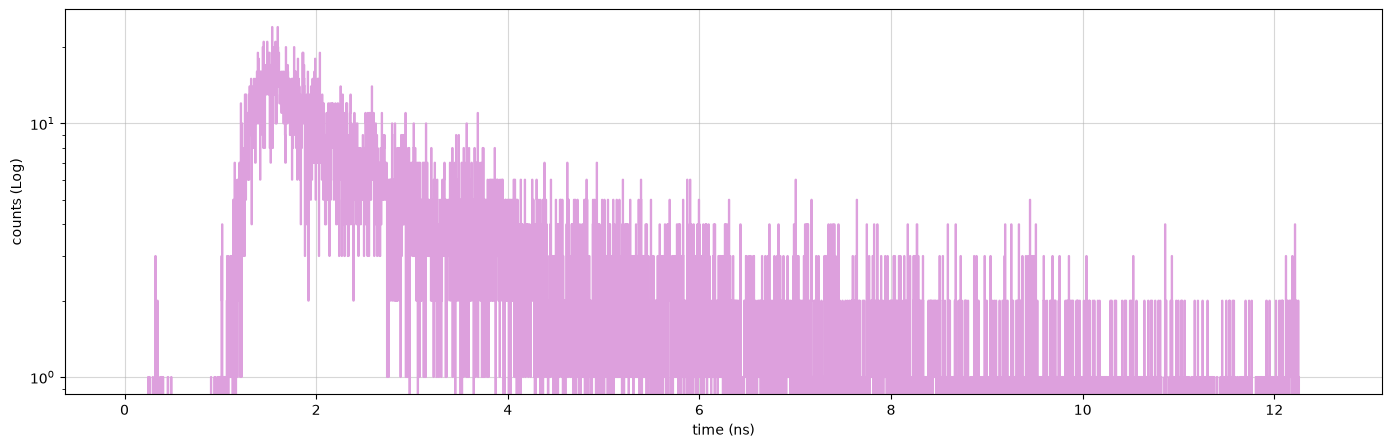

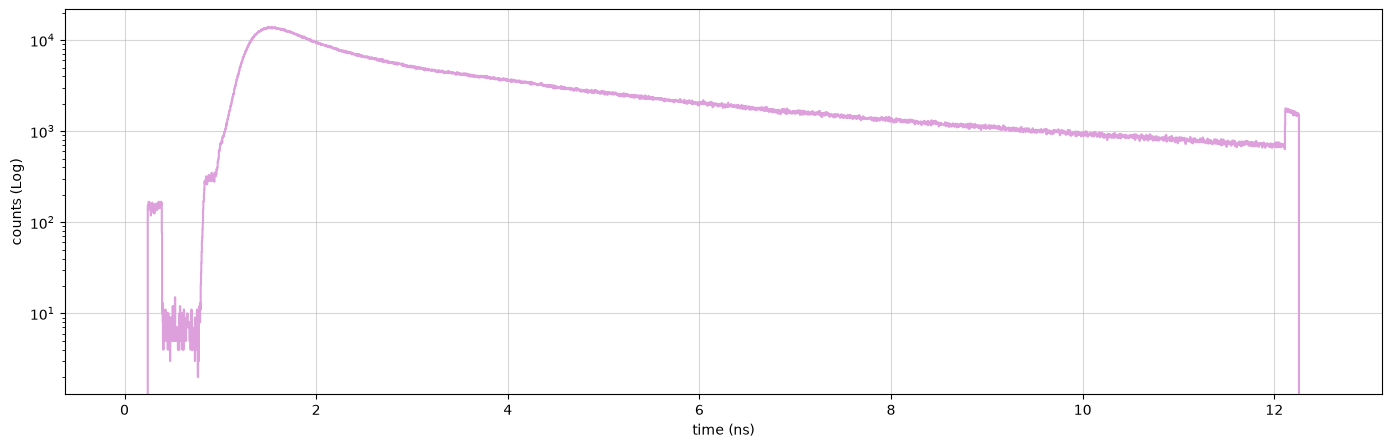

In [20]:
image = xr.DataArray(
    tiff.imread('./data/FLIM_4_flim_Ch1.tif'),
    dims = ("time", "x", "y"),
    name = "image",
)
max_pixel = phplt.image_flattener(image)

phplt.pixel_plot(image, max_pixel)    # pixel with highest count
phplt.global_image_plot(image)    # whole image

<h3> Flat image, pixel and total plot

Test on image from phasor.py (embryo of zebrafish)

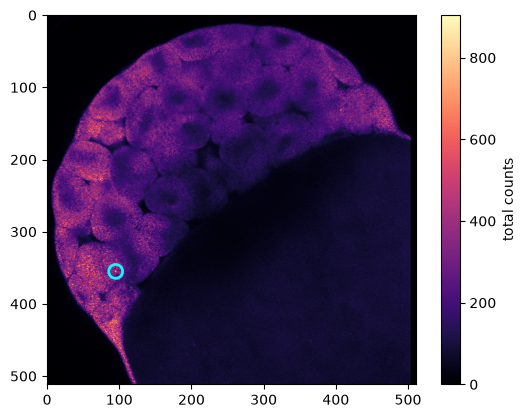

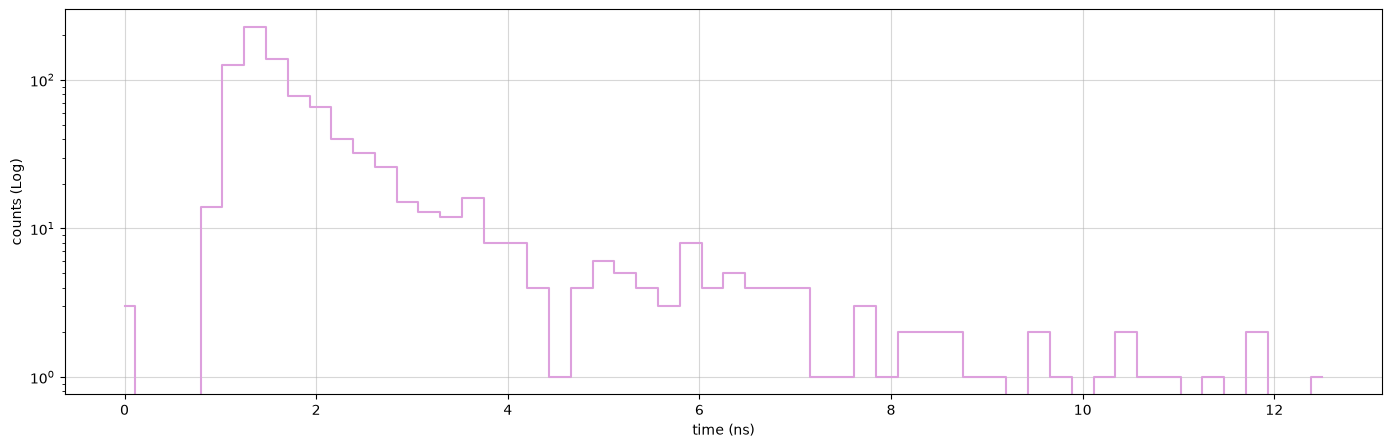

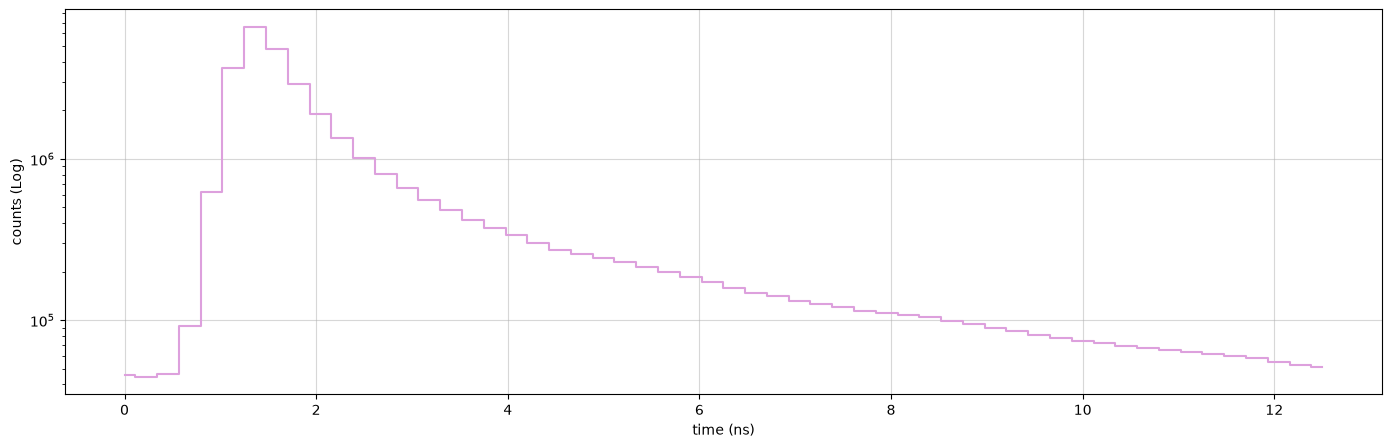

In [24]:
# https://zenodo.org/records/8046636    # I got my data from here

embryopic = xr.DataArray(
    tiff.imread(fetch('Embryo.tif')),
    dims = ("time", "x", "y"),
    name = "embryopic",
)

fluopic = xr.DataArray(
    tiff.imread(fetch('Fluorescein_Embryo.tif')),
    dims = ("time", "x", "y"),
    name = "fluopic",
)

max_pixel1 = phplt.image_flattener(embryopic)
phplt.pixel_plot(embryopic, max_pixel1)
phplt.global_image_plot(embryopic)

<h3> Calibration flat image, pixel and total plot (fluorescein was used, with a known tau of 4ns)

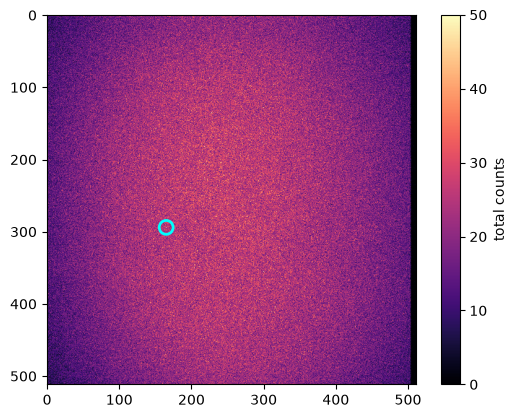

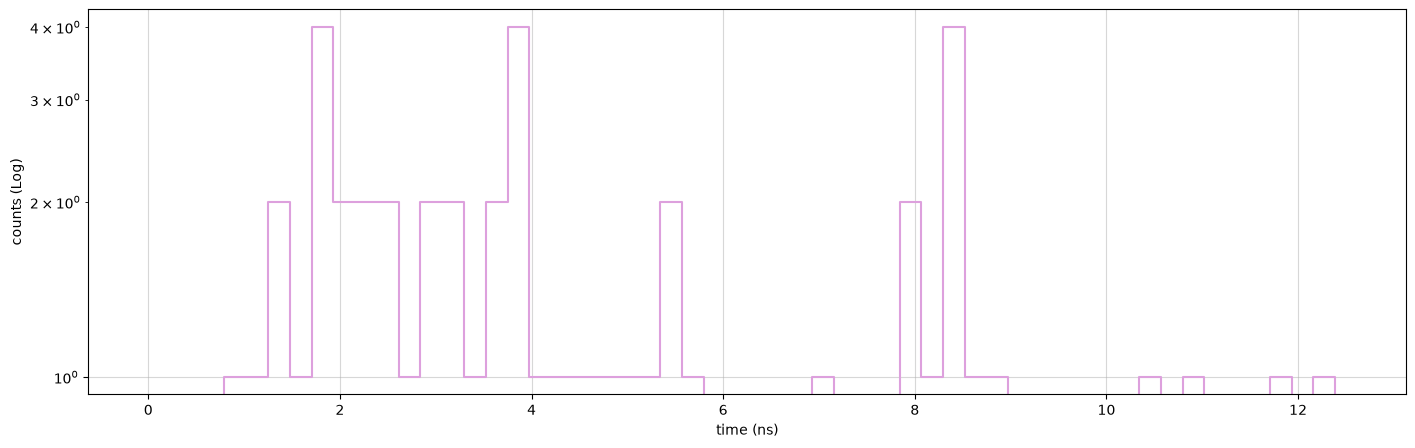

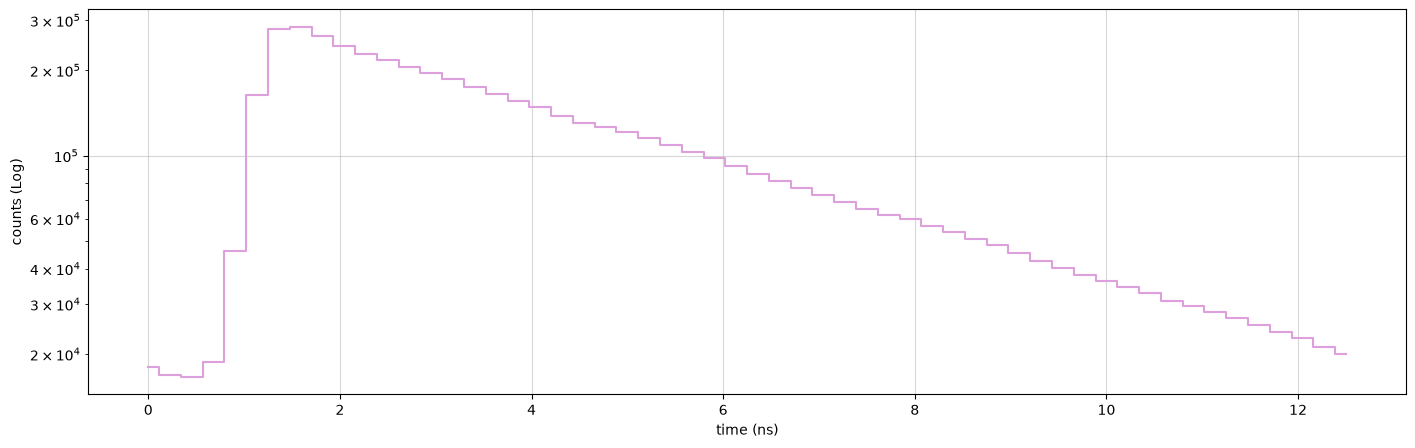

In [26]:
max_pixel2 = phplt.image_flattener(fluopic)
phplt.pixel_plot(fluopic, max_pixel2)
phplt.global_image_plot(fluopic)

<h3> IRF deconvolution

In [27]:
T_laser = 12.5
τ_fluor_true = 4.0      # LT of fluorescein (known value)    

G_irf, S_irf = extract_irf(fluopic, τ_fluor_true, T_laser)      # IRF from deconvolution
G_valid, S_valid = filter_image_phasors(embryopic, threshold_pct = 0.05)
G_clean, S_clean = phasor_deconv(G_valid, S_valid, G_irf, S_irf)    # deconvolution

Max count: 905 γ. Threshold: 45 γ.
Pixels over threshold: 193969/262144


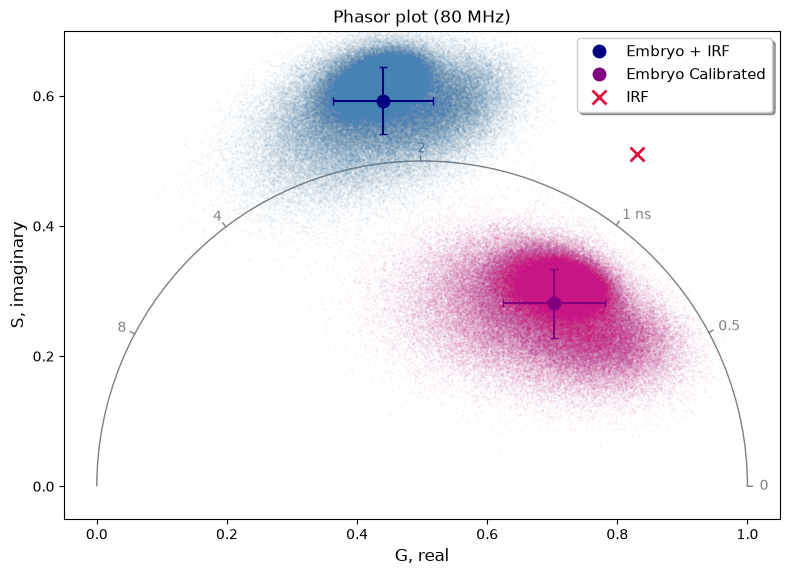

In [28]:
df_raw = pd.DataFrame({
    'G': G_valid.values,
    'S': S_valid.values
})

df_clean = pd.DataFrame({
    'G': G_clean.values,
    'S': S_clean.values
})

raw_mean = df_raw[['G', 'S']].mean()
raw_std = df_raw[['G', 'S']].std()

clean_mean = df_clean[['G', 'S']].mean()
clean_std = df_clean[['G', 'S']].std()

points_comparison = [
    {
        'G': df_raw['G'],
        'S': df_raw['S'],
        'color': 'steelblue',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.05,
        'linestyle': 'None'
    },
    {
        'G': df_clean['G'],
        'S': df_clean['S'],
        'color': 'mediumvioletred',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.05,
        'linestyle': 'None'
    },
    {
        'G': raw_mean['G'],
        'S': raw_mean['S'],
        'xerr': raw_std['G'],
        'yerr': raw_std['S'],
        'label': 'Embryo + IRF',
        'color': 'navy',
        'marker': 'o',
        'markersize': 9,
        'zorder': 6
    },
    {
        'G': clean_mean['G'],
        'S': clean_mean['S'],
        'xerr': clean_std['G'],
        'yerr': clean_std['S'],
        'label': 'Embryo Calibrated',
        'color': 'purple',
        'marker': 'o',
        'markersize': 9,
        'zorder': 6
    },
    {
        'G': G_irf,
        'S': S_irf,
        'label': 'IRF',
        'color': 'crimson',
        'marker': 'x',
        'markersize': 10,
        'markeredgewidth': 2,
        'linestyle': 'None',
        'zorder': 7
    }
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_comparison)


# 5. Density filter

Inizio facendo un riassunto teorico per verificare velocemente se ho capito bene.

Quello che mi interessa fare è un bg filter sul piano dei fasori. Ovvero:
- NON sull'immagine iniziale (rischio di eliminare strutture meno luminose perché sottili)
- NON sulla matrice G,S -> qui i punti sono vicini per posizione spaziale e non per posizione sul piano dei fasori (similitudine di tempo di decadimento). Ricadrei nello stesso errore del punto precedente